# Random Forest and ANN for California house prices

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from tensorflow import keras
from tensorflow.keras import layers

from src.load_data import get_dataset, split_data
from src.metrics import metrics, plot_residual_curve
from src.tree_nn_pipeline import add_ratios, log_fix, clip_scaled, get_tree_preprocessor, get_nn_preprocessor

/Users/yugamdeepgoyal/my_gpu/tf_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = get_dataset()
X_train, X_test, y_train, y_test = split_data(df)
X_train.shape, X_test.shape

((16512, 9), (4128, 9))

## Random Forest

In [3]:
def build_rf():
    return Pipeline([
        ("ratios", FunctionTransformer(add_ratios)),
        ("prep", get_tree_preprocessor()),
        ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ])

def tune_rf(X, y):
    grid = {
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": [0.4, 0.7, 1.0],
    }
    search = GridSearchCV(build_rf(), grid, cv=3, scoring="neg_root_mean_squared_error")
    search.fit(X, y)
    print("best params:", search.best_params_)
    print("cv rmse:", -search.best_score_)
    return search.best_estimator_

rf = tune_rf(X_train, y_train)

best params: {'model__max_features': 0.4, 'model__min_samples_leaf': 1}
cv rmse: 49494.46207691408


In [4]:
rf_train_pred = rf.predict(X_train)
rf_pred = rf.predict(X_test)

print("TRAINING")
metrics(y_train, rf_train_pred)

print("TESTING")
metrics(y_test, rf_pred)

TRAINING
Mean absolute Error: 11743.919067344963
Mean squared Error: 318000506.045805
Root Mean squared error: 17832.56868894117
R2 Score: 0.976211423612289
TESTING
Mean absolute Error: 31459.08859738372
Mean squared Error: 2314924518.2275834
Root Mean squared error: 48113.66249026968
R2 Score: 0.823343356412656


In [5]:
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="r2")

print("R2 per fold:", scores)
print("Mean R2:", scores.mean())
print("Std R2:", scores.std())

R2 per fold: [0.82519309 0.8129658  0.82432589 0.82013112 0.82090762]
Mean R2: 0.8207047041579074
Std R2: 0.004324800320786052


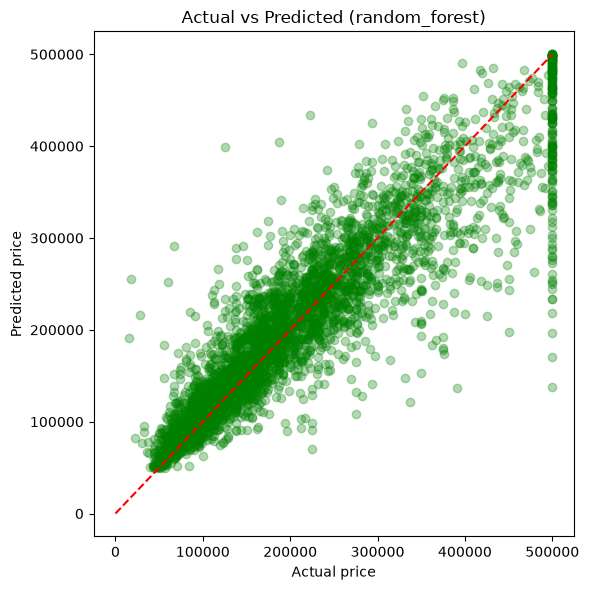

In [6]:
def actual_vs_pred(y_true, y_pred, name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    lims = [0, max(y_true.max(), y_pred.max())]

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.3, color="green")
    plt.plot(lims, lims, color="red", linestyle="dashed")
    plt.xlabel("Actual price")
    plt.ylabel("Predicted price")
    plt.title(f"Actual vs Predicted ({name})")
    plt.tight_layout()
    plt.savefig(f"images/{name}_actual_vs_predicted.png")
    plt.show()

actual_vs_pred(y_test, rf_pred, "random_forest")

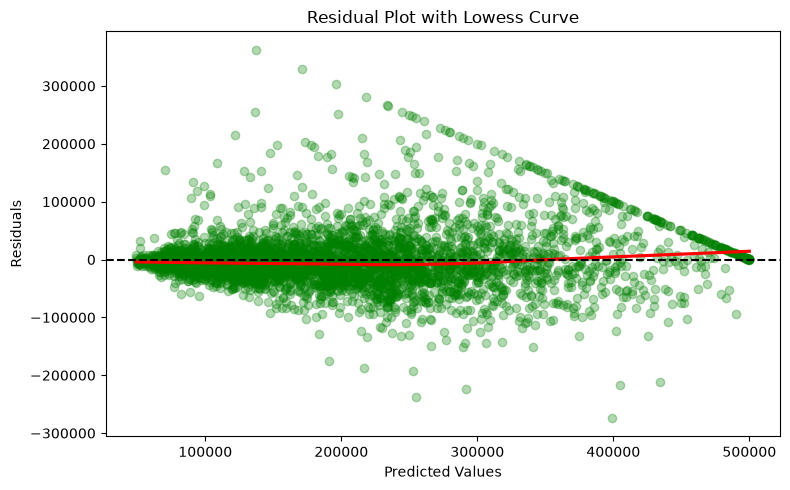

In [7]:
plot_residual_curve(y_test, rf_pred, "random_forest")

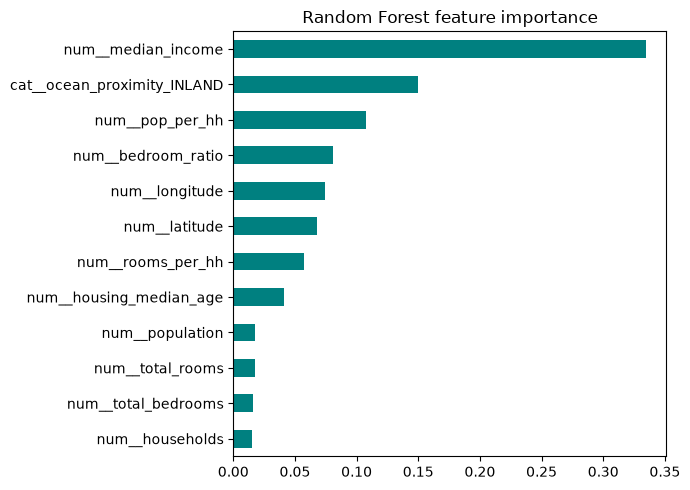

num__median_income             0.334550
cat__ocean_proximity_INLAND    0.149953
num__pop_per_hh                0.107951
num__bedroom_ratio             0.081090
num__longitude                 0.074537
num__latitude                  0.068035
num__rooms_per_hh              0.057179
num__housing_median_age        0.041482
num__population                0.017279
num__total_rooms               0.017203
dtype: float64

In [8]:
def plot_importance(model, top=12):
    names = model.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(model.named_steps["model"].feature_importances_, index=names)
    imp = imp.sort_values(ascending=False)

    imp.head(top).sort_values().plot(kind="barh", figsize=(7, 5), color="teal")
    plt.title("Random Forest feature importance")
    plt.tight_layout()
    plt.savefig("images/rf_feature_importance.png")
    plt.show()
    return imp

importance = plot_importance(rf)
importance.head(10)

In [9]:
joblib.dump(rf, "models/random_forest.joblib")

['models/random_forest.joblib']

## ANN

In [10]:
# validation set comes out of train only, test stays untouched
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

nn_prep = Pipeline([
    ("ratios", FunctionTransformer(add_ratios)),
    ("log", FunctionTransformer(log_fix)),
    ("prep", get_nn_preprocessor()),
    ("clip", FunctionTransformer(clip_scaled)),
])
X_tr_s = nn_prep.fit_transform(X_tr)
X_val_s = nn_prep.transform(X_val)
X_test_s = nn_prep.transform(X_test)

y_scaler = StandardScaler()
y_tr_s = y_scaler.fit_transform(y_tr.to_frame()).ravel()
y_val_s = y_scaler.transform(y_val.to_frame()).ravel()

X_tr_s.shape, X_val_s.shape, X_test_s.shape

((14035, 16), (2477, 16), (4128, 16))

In [11]:
def build_ann(units, lr, n_features):
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu"))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="mse", metrics=["mae"])
    return model

def train_ann(units, lr, batch_size):
    keras.utils.set_random_seed(42)
    model = build_ann(units, lr, X_tr_s.shape[1])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    hist = model.fit(
        X_tr_s, y_tr_s,
        validation_data=(X_val_s, y_val_s),
        epochs=200, batch_size=batch_size,
        callbacks=[stop], verbose=0,
    )
    return model, hist

def run_experiments(configs):
    results = []
    for units, lr, batch_size in configs:
        model, hist = train_ann(units, lr, batch_size)
        val_rmse = np.sqrt(min(hist.history["val_loss"])) * y_scaler.scale_[0]
        results.append((units, lr, batch_size, val_rmse, model, hist))
        print(units, lr, batch_size, "| epochs:", len(hist.history["loss"]), "| val rmse:", round(val_rmse))
    return results

configs = [
    ((64, 32), 1e-3, 64),
    ((128, 64, 32), 1e-3, 64),
    ((128, 64, 32), 5e-4, 128),
    ((256, 128, 64), 1e-3, 64),
]
results = run_experiments(configs)

2026-11-14 10:05:00.293564: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-14 10:05:00.293586: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-11-14 10:05:00.293589: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-11-14 10:05:00.293604: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-14 10:05:00.293610: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-11-14 10:05:00.502520: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


(64, 32) 0.001 64 | epochs: 17 | val rmse: 69637
(128, 64, 32) 0.001 64 | epochs: 33 | val rmse: 86084
(128, 64, 32) 0.0005 128 | epochs: 18 | val rmse: 70145
(256, 128, 64) 0.001 64 | epochs: 17 | val rmse: 150143


In [12]:
best = min(results, key=lambda r: r[3])
ann, history = best[4], best[5]
print("best config:", best[:4])
ann.summary()

best config: ((64, 32), 0.001, 64, 69636.57903000597)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,605 (37.52 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,404 (25.02 KB)

In [13]:
def ann_predict(model, X_s):
    p = model.predict(X_s, verbose=0).ravel()
    return y_scaler.inverse_transform(p.reshape(-1, 1)).ravel()

ann_train_pred = ann_predict(ann, X_tr_s)
ann_pred = ann_predict(ann, X_test_s)

print("TRAINING")
metrics(y_tr, ann_train_pred)

print("TESTING")
metrics(y_test, ann_pred)

TRAINING
Mean absolute Error: 49960.62710176522
Mean squared Error: 4589772934.983572
Root Mean squared error: 67747.86295510414
R2 Score: 0.6545390140123575
TESTING
Mean absolute Error: 51734.2803785228
Mean squared Error: 4919842397.383102
Root Mean squared error: 70141.5882154311
R2 Score: 0.6245567239635732


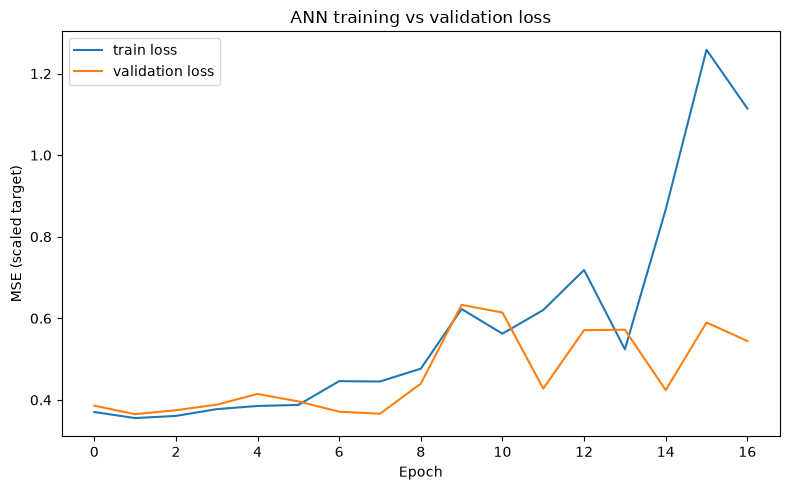

In [14]:
def plot_loss(history):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE (scaled target)")
    plt.title("ANN training vs validation loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig("images/ann_loss_curve.png")
    plt.show()

plot_loss(history)

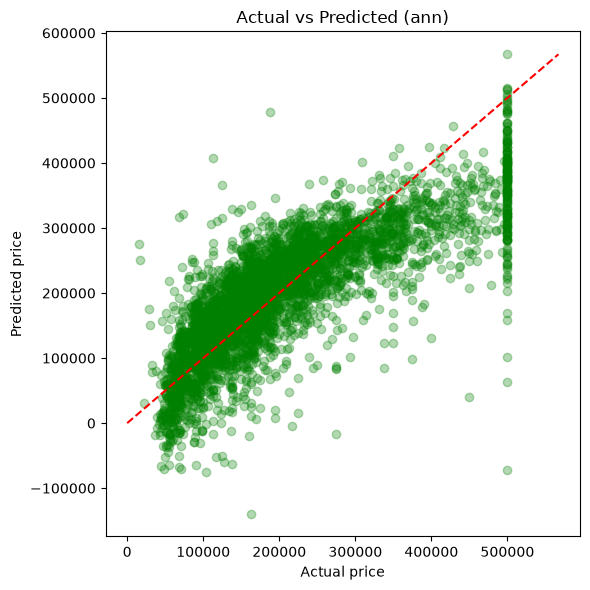

In [15]:
actual_vs_pred(y_test, ann_pred, "ann")

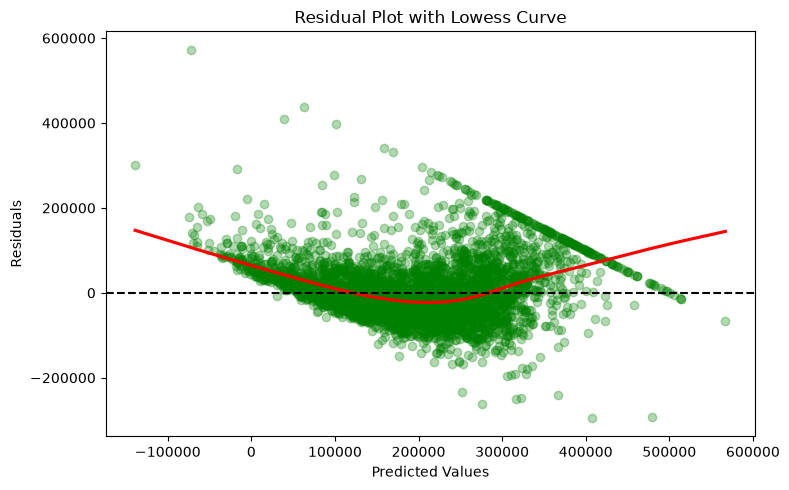

In [16]:
plot_residual_curve(y_test, ann_pred, "ann")

In [17]:
ann.save("models/ann.keras")
joblib.dump({"prep": nn_prep, "y_scaler": y_scaler}, "models/ann_preprocessing.joblib")

['models/ann_preprocessing.joblib']